In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
import warnings
import joblib


In [3]:
iris = pd.read_csv('Iris.csv')
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
iris = iris.drop('Id', axis = 1)

In [5]:
print(iris.isnull().sum())


SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [6]:
label_encoder = LabelEncoder()
iris['species_encoded'] = label_encoder.fit_transform(iris['Species'])

In [7]:
print('\nEncoded Classes:')
print(label_encoder.classes_)


Encoded Classes:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [8]:
print(f'\nDataset Shape {iris.shape}')


Dataset Shape (150, 6)


In [9]:
iris.groupby('Species').mean()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,species_encoded
Species,,,,,
Iris-setosa,5.006,3.418,1.464,0.244,0.0
Iris-versicolor,5.936,2.770,4.260,1.326,1.0
Iris-virginica,6.588,2.974,5.552,2.026,2.0


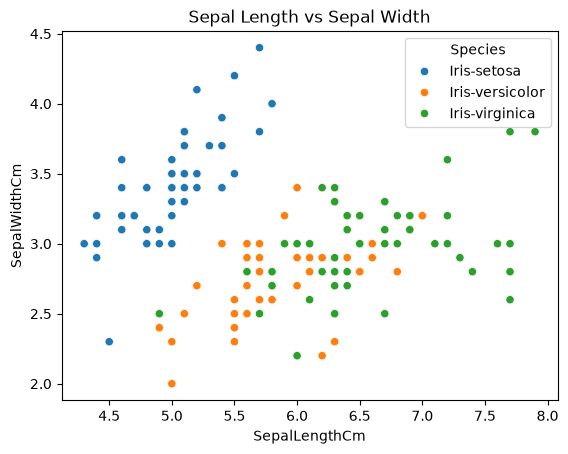

In [10]:
sns.scatterplot(x ='SepalLengthCm', y = 'SepalWidthCm', hue = 'Species', data = iris)
plt.title('Sepal Length vs Sepal Width')
plt.show()

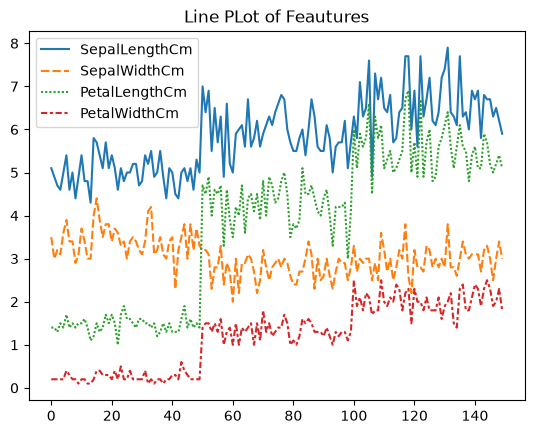

In [11]:
sns.lineplot(data = iris.drop(['Species', 'species_encoded'], axis = 1))
plt.title('Line PLot of Feautures')
plt.show()

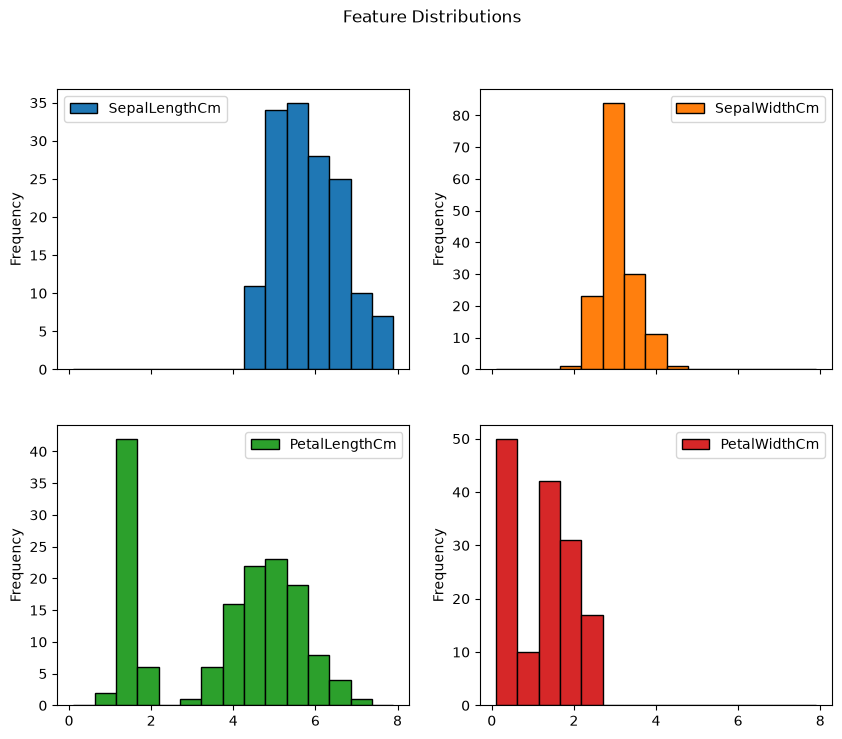

In [12]:
iris.drop(['Species', 'species_encoded'], axis = 1).plot.hist(subplots = True, layout = (2,2), figsize = (10,8), bins = 15, edgecolor = 'black')
plt.suptitle('Feature Distributions')
plt.show()

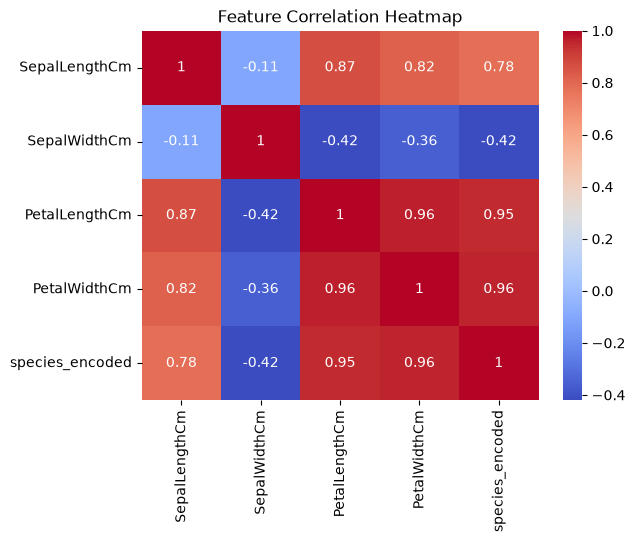

In [13]:
numeric_iris = iris.drop('Species', axis = 1)
sns.heatmap(numeric_iris.corr(), annot = True, cmap = 'coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

In [14]:
X = iris.drop(['Species', 'species_encoded'], axis = 1)
y = iris['species_encoded']

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.4, random_state= 42, stratify= y)

In [16]:
svm = SVC(kernel = 'rbf', gamma = 0.1, C = 1.0)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)

print('\nSVM Classification Report:')
print(metrics.classification_report(y_test, y_pred_svm))
print(f'SVM Accuracy: {metrics.accuracy_score(y_test, y_pred_svm):.4f}')


SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       0.95      0.95      0.95        20
           2       0.95      0.95      0.95        20

    accuracy                           0.97        60
   macro avg       0.97      0.97      0.97        60
weighted avg       0.97      0.97      0.97        60

SVM Accuracy: 0.9667


In [17]:
joblib.dump(svm, 'model.pkl')

['model.pkl']